# 02 - Binary'den Görüntüye Dönüştürme ve Ön İşleme

1. **Dönüştürme:** Bir dosyanın byte'larının nasıl gri tonlamalı görüntüye dönüştüğünü gösteriyoruz. Örnek olarak **zararsız** bir dosya kullanıyoruz: bilgisayardaki Python yorumlayıcısı (`python.exe`).
2. **Ön işleme:** Malimg görüntülerini gri tonlamalı okuyup 256×256'ya getiriyor ve `data/processed/images_256/` altına kaydediyoruz.

> Dosyalar hiçbir zaman çalıştırılmaz, yalnızca byte'ları okunur.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import numpy as np
import matplotlib.pyplot as plt

import config
from src import binary_to_image as b2i
from src.preprocess import read_gray, resize, preprocess_dataset, PROCESSED_IMG_DIR
from src.data_loader import load_dataset_index, class_distribution
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Genişlik tablosu (Nataraj vd., 2011)

Görüntü genişliği dosya boyutuna göre seçilir, yükseklik ise byte sayısına göre kendiliğinden belirlenir.

In [2]:
import pandas as pd
onceki = 0
rows = []
for limit, w in b2i.WIDTH_TABLE:
    rows.append({"Dosya boyutu": f"{onceki}–{limit} KB" if limit != float('inf') else f"> {onceki} KB", "Genişlik (px)": w})
    onceki = limit
pd.DataFrame(rows)

,Dosya boyutu,Genişlik (px)
0,0–10 KB,32
1,10–30 KB,64
2,30–60 KB,128
3,60–100 KB,256
4,100–200 KB,384
5,200–500 KB,512
6,500–1000 KB,768
7,> 1000 KB,1024


## 2. Zararsız bir dosyayı dönüştürme

In [3]:
ornek = Path(sys.executable)          # python.exe — zararsız
data = ornek.read_bytes()
arr = b2i.bytes_to_array(data)
print(f"Dosya: {ornek.name}  |  {len(data)/1024:.1f} KB  ->  {arr.shape[1]} x {arr.shape[0]} piksel")
print("İlk 16 byte :", list(data[:16]))
print("İlk 16 piksel:", arr[0, :16].tolist())   # byte'lar birebir piksel

Dosya: python.exe  |  249.3 KB  ->  512 x 499 piksel
İlk 16 byte : [77, 90, 144, 0, 3, 0, 0, 0, 4, 0, 0, 0, 255, 255, 0, 0]
İlk 16 piksel: [77, 90, 144, 0, 3, 0, 0, 0, 4, 0, 0, 0, 255, 255, 0, 0]


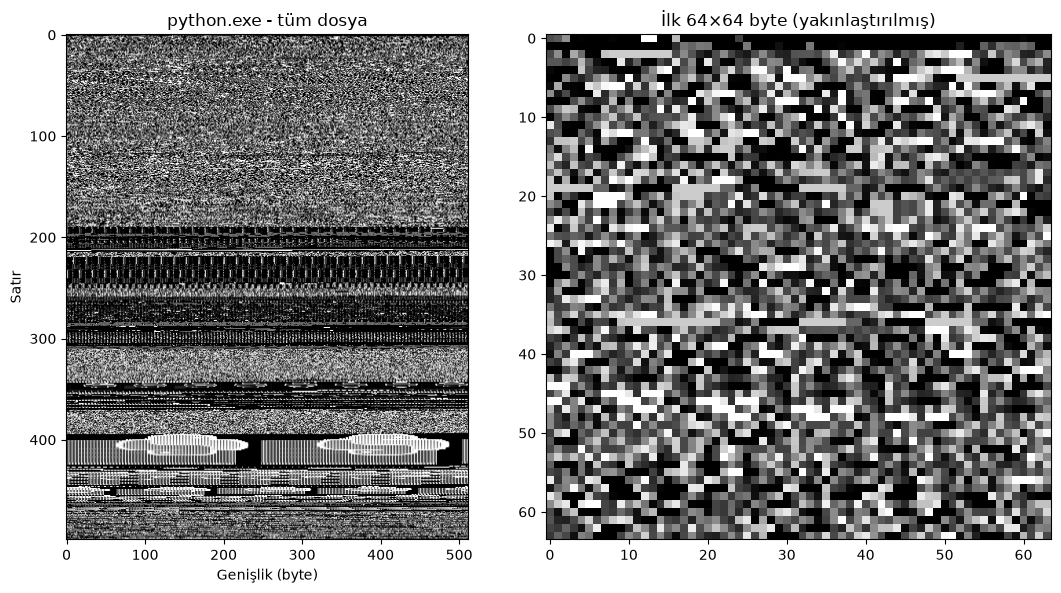

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].imshow(arr, cmap="gray", aspect="auto")
axes[0].set_title(f"{ornek.name} - tüm dosya")
axes[0].set_xlabel("Genişlik (byte)"); axes[0].set_ylabel("Satır")

zoom = arr[: min(64, len(arr)), :64]
axes[1].imshow(zoom, cmap="gray", interpolation="nearest")
axes[1].set_title("İlk 64×64 byte (yakınlaştırılmış)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "02_donusturme_ornegi.png", dpi=150)
plt.show()

Görüntüdeki farklı bölgeler PE dosyasının bölümlerine karşılık gelir: başlık, kod (`.text`), veri (`.data`) ve kaynaklar (`.rsrc`). Sıfırlarla dolu alanlar siyah, sıkıştırılmış veya şifreli alanlar gürültülü görünür. LBP ve GLCM'nin yakalamaya çalıştığı doku farkları bunlardır.

## 3. Ön işleme: 256×256'ya getirme

Bu bölümden itibaren Malimg'in `data/raw/malimg_paths/` altında olması gerekiyor.

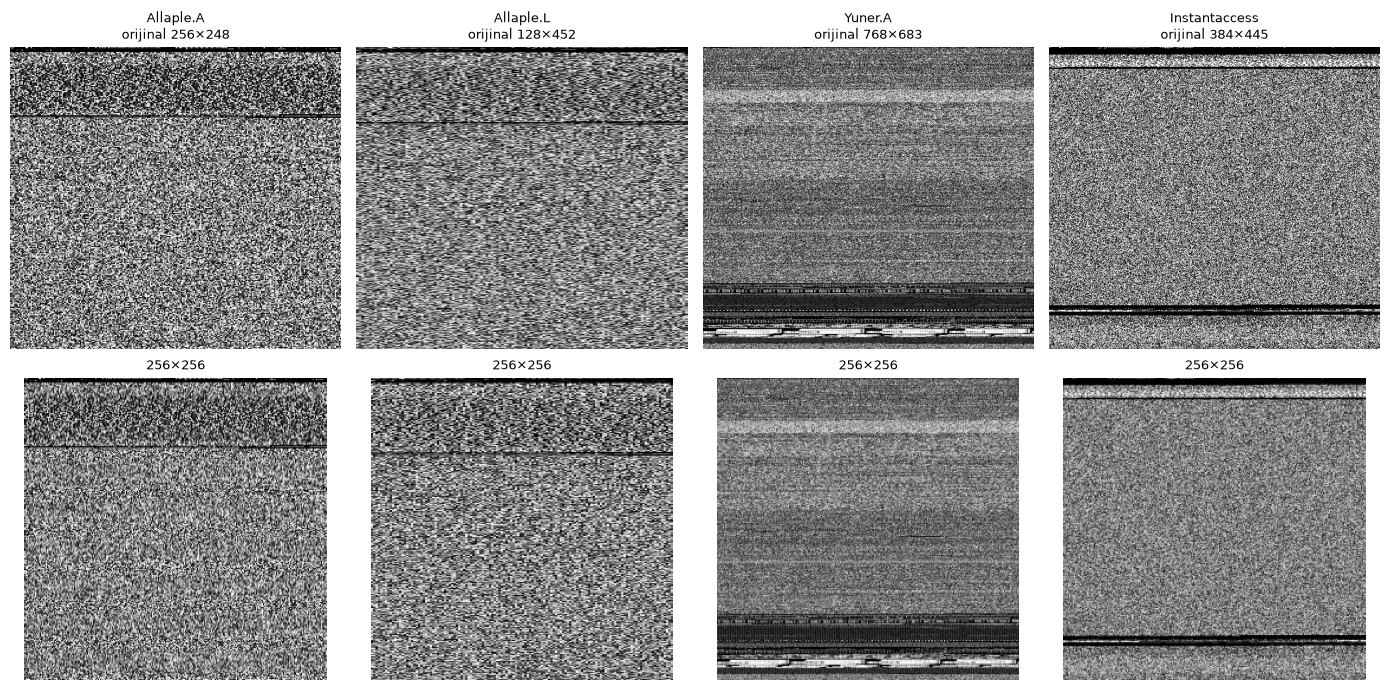

In [5]:
df = load_dataset_index(config.MALIMG_DIR)
dist = class_distribution(df)
ornekler = [df[df["family"] == f]["path"].iloc[0] for f in dist.index[:4]]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, p in enumerate(ornekler):
    orj = read_gray(p)
    yeni = resize(orj)
    axes[0, i].imshow(orj, cmap="gray", aspect="auto"); axes[0, i].set_title(f"{Path(p).parent.name}\norijinal {orj.shape[1]}×{orj.shape[0]}", fontsize=9)
    axes[1, i].imshow(yeni, cmap="gray");              axes[1, i].set_title(f"256×256", fontsize=9)
    for ax in axes[:, i]: ax.axis("off")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "02_onisleme_once_sonra.png", dpi=150)
plt.show()

## 4. Tüm veri setini işleme

İlk çalıştırma birkaç dakika sürebilir. Daha önce işlenmiş dosyalar atlanır, bu yüzden tekrar çalıştırmak hızlıdır.

In [6]:
processed = preprocess_dataset(df)
print(f"{len(processed)} görüntü -> {PROCESSED_IMG_DIR}")
processed["family"].value_counts().head()

Ön işleme: 100%|██████████| 9339/9339 [00:04<00:00, 1879.58it/s]


9339 görüntü -> C:\Users\Asus\OneDrive\Masaüstü\BP\malware-image-classification\data\processed\images_256


family
Allaple.A        2949
Allaple.L        1591
Yuner.A           800
Instantaccess     431
VB.AT             408
Name: count, dtype: int64

In [7]:
# Kontrol: tüm çıktılar 256x256 mı?
from PIL import Image
boyutlar = {Image.open(p).size for p in processed["path"].sample(min(200, len(processed)), random_state=config.RANDOM_STATE)}
print("Bulunan boyutlar:", boyutlar)
assert boyutlar == {config.IMG_SIZE}

Bulunan boyutlar: {(256, 256)}


## 5. Notlar

- Dönüştürme örneği için kullanılan dosya ve boyutu:
- Yeniden boyutlandırmada gözlenen bilgi kaybı (özellikle çok büyük dosyalarda):
- İşlem süresi: